# PTM3D notebook 07: an asteroid without and with a shape model, at a flyby and over an orbit

This notebook follows the main line of [tutorial 6](../06_asteroids.md). It starts with a
spherical asteroid defined entirely in the configuration, then uses the DAMIT shape model and
spin state of (433) Eros on its JPL Horizons orbit. With Eros it looks at two kinds of time
window, six hours around the NEAR Shoemaker flyby of 23 December 1998, and one whole orbit of
643 days. Each section ends with the temperatures in a form that can be compared with
observations, as a map at one time, series at chosen sites, and a table.

**Cost:** the sphere and the Eros flyby window take under a minute each on a workstation and a
few minutes on four cores. The orbit of section 4 takes about 10 minutes on four cores, and it is
run from a terminal (the cell says how).

**Needs:** the leap-seconds kernel (`python3 scripts/fetch_kernels.py --bodies moon`), and an
internet connection once, to download the Eros shape, spin state and ephemeris (0.3 MB from
DAMIT and JPL Horizons) with `examples/python/fetch_asteroid.py`.

In [1]:
import csv
import subprocess
import sys

import numpy as np
from ptm import paths, plots, Results, run as engine

pre = paths.preflight(["examples/asteroid_sphere.yaml", "examples/asteroid_eros.yaml",
                       "data/kernels/lsk/naif0012.tls"], engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()
ROOT = pre.root
plt = plots.styled()

def run_once(config, outdir):
    # Run the model unless its output is already there, for example from tutorial 6.
    if not (ROOT / outdir / "metadata.txt").is_file():
        engine.run_engine(ROOT / config, show=("Simulation completed in",))

found    <repo>/build/bin/ptm_thermal_sim
found    examples/asteroid_sphere.yaml
found    examples/asteroid_eros.yaml
found    data/kernels/lsk/naif0012.tls

Repo root: <repo>
Engine:    <repo>/build/bin/ptm_thermal_sim


## 1. A sphere defined in the configuration

`examples/asteroid_sphere.yaml` describes a body 1 km across with a 6-hour rotation, zero
obliquity, thermal inertia 200 SI and Bond albedo 0.10, on a circular orbit at 1.3 AU. The
`generic_body:` block of the configuration holds the orbit, the spin and the surface properties,
and the model builds a sphere of 5,120 faces.

In [2]:
run_once("examples/asteroid_sphere.yaml", "output/asteroid_sphere")
sphere = Results(ROOT / "output" / "asteroid_sphere", body_radius_km=0.5)
tmax, tmin = sphere.stat("temperature", "max"), sphere.stat("temperature", "min")
equator = sphere.faces_in_band(-6, 6)
print(sphere)
print(f"equator: T_max {tmax[equator].mean():.1f} K, T_min {tmin[equator].mean():.1f} K")

<Results asteroid_sphere: 5120 faces, 5 per-step field(s), 96 steps>
equator: T_max 313.6 K, T_min 198.1 K


The local solar time of a face is its longitude relative to the sub-solar longitude, at 15° per
hour from noon. Plotted against local time, the series of each face is one diurnal curve.

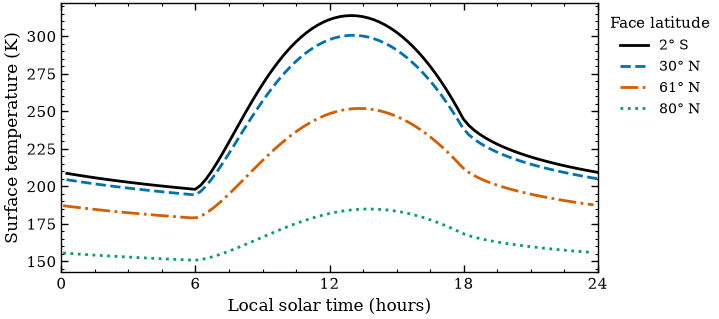

In [3]:
n_steps = len(sphere.times().et)
sun_lon = np.array([sphere.subsolar_latlon(i)[1] for i in range(n_steps)])
fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.2), constrained_layout=True)
for lat in (0, 30, 60, 80):
    face = sphere.face_at(lat, 0.0)
    _, T = sphere.series("temperature", face=face)
    local_time = (12.0 + (sphere.lon[face] - sun_lon) / 15.0) % 24.0
    order = np.argsort(local_time)
    face_lat = sphere.lat[face]          # the face nearest the requested latitude
    ax.plot(local_time[order], T[order],
            label=f"{abs(face_lat):.0f}° {'N' if face_lat >= 0 else 'S'}")
ax.set_xlabel("Local solar time (hours)")
ax.set_ylabel("Surface temperature (K)")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 6))
ax.legend(title="Face latitude", loc="upper left", bbox_to_anchor=(1.0, 1.0));

The peak comes after local noon and the minimum shortly before sunrise, because the regolith stores
the heat of the day. The thermal parameter of Spencer et al. (1989),
$\Theta = \Gamma \sqrt{\omega} / (\varepsilon \sigma T_\mathrm{ss}^3)$, measures this. For this
body $\Theta \approx 1.6$, and the night side stays far above the temperature a surface without
thermal inertia would reach.

## 2. Eros: shape, spin state and orbit

The shape model of (433) Eros in DAMIT (model 1714, 1,708 faces) comes with the pole direction,
the sidereal period and the rotational phase at an epoch. The script `fetch_asteroid.py` downloads
the shape and spin from DAMIT and an SPK ephemeris from JPL Horizons covering 1993 to 1999, and
writes the `generic_body` block that `examples/asteroid_eros.yaml` reads. Tutorial 6, section
"A shape model from DAMIT: Eros", describes each step.

In [4]:
if not (ROOT / "data" / "asteroids" / "eros" / "generic_body.yaml").is_file():
    subprocess.run([sys.executable, "examples/python/fetch_asteroid.py", "433", "--damit-id", "1714",
                    "--start", "1993-01-01", "--stop", "1999-01-01",
                    "--epoch", "1998-12-23T15:41:23", "--outdir", "data/asteroids/eros"],
                   cwd=ROOT, check=True)
print((ROOT / "data" / "asteroids" / "eros" / "generic_body.yaml").read_text()[:900])

generic_body:
  name: 433 Eros (A898 PA)
  ephemeris_source: spice            # or keplerian, to use the elements below
  spice_metakernel: data/asteroids/eros/metakernel.tm
  naif_id: '20000433'
  shape:
    type: custom_mesh
    mesh_file: data/asteroids/eros/shape.obj
    radius_km: 8.410
  orbit:
    semi_major_axis_au: 1.45826243
    eccentricity: 0.22288405
    inclination_deg: 10.830128
    lon_ascending_node_deg: 304.430859
    arg_perihelion_deg: 178.613081
    mean_anomaly_deg: 209.049706
    epoch: 'JD 2451171.154470'
  spin:
    period_hours: 5.27025528
    pole_ra_deg: 11.290620
    pole_dec_deg: 16.811616
    prime_meridian_deg: 305.978632
    epoch: 'JD 2451545.000000'



## 3. A flyby window

`examples/asteroid_eros.yaml` integrates 500 rotations of spin-up (about 110 days) and then writes
six hours of output at five-minute steps, from 15:41:23 to 21:36:23 UTC on 23 December 1998. The
closest approach of NEAR Shoemaker was at 18:41:23 UTC. Tutorial 6 ("The spin-up and the basal
heat flow") explains why the spin-up must be this long. With 50 rotations, faces that have been
in seasonal darkness are still far too cold.

In [5]:
run_once("examples/asteroid_eros.yaml", "output/asteroid_eros")
eros = Results(ROOT / "output" / "asteroid_eros", body_radius_km=8.41)
utc = list(eros.times().utc)
flyby = utc.index("1998-12-23T18:41:23.000")
T_flyby = eros.field("temperature", step=flyby)
sun_lat, sun_lon = eros.subsolar_latlon(flyby)
print(f"{eros.n_faces} faces, output {flyby} of {len(utc)} is at {utc[flyby]} UTC")
print(f"sub-solar point at latitude {sun_lat:.1f}, longitude {sun_lon:.1f} degrees")
print(f"surface temperature {T_flyby.min():.1f} to {T_flyby.max():.1f} K, "
      f"area-weighted mean {np.average(T_flyby, weights=eros.face_areas_m2):.1f} K")

1708 faces, output 36 of 72 is at 1998-12-23T18:41:23.000 UTC
sub-solar point at latitude -34.5, longitude 14.5 degrees
surface temperature 50.7 to 268.3 K, area-weighted mean 178.9 K


The shape is drawn with each facet where it is, colored by its temperature at closest approach,
from two opposite directions.

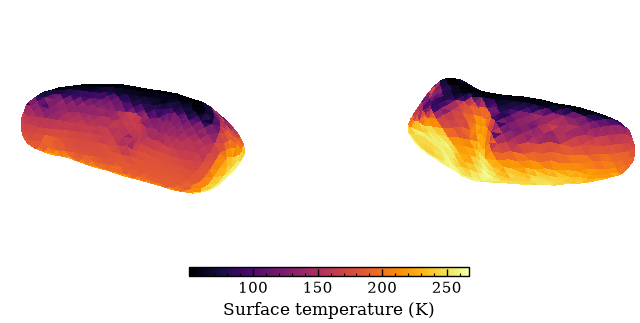

In [6]:
mesh = eros.mesh
fig = plt.figure(figsize=(plots.DOUBLE_W, 3.4))
for k, azim in enumerate((-60, 120)):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    art = plots.shape(ax, mesh["vertices"], mesh["faces"], T_flyby, elev=15, azim=azim, axis_labels=None)
    ax.set_axis_off()
    ax.set_box_aspect((1, 1, 1), zoom=1.7)
plots.colorbar(fig, art, fig.axes, "Surface temperature (K)", orientation="horizontal",
               shrink=0.5, pad=0.0, aspect=30)
fig.subplots_adjust(left=0.0, right=1.0, top=1.0, bottom=0.2, wspace=0.0);

Through the window each face completes a little more than one rotation. The figure follows the
four sites of `examples/asteroid_sites.csv`, each at the face nearest its latitude and longitude
(given in parentheses in the legend, in degrees).

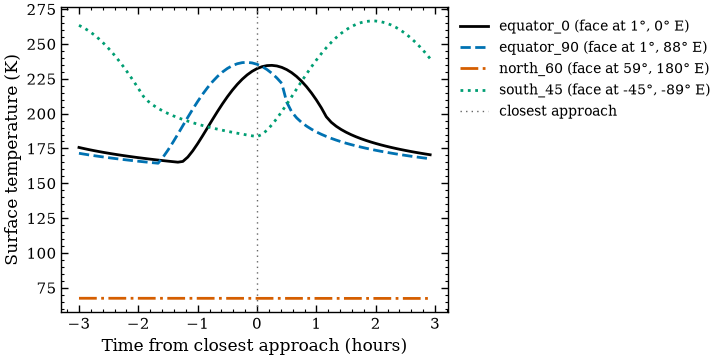

In [7]:
with open(ROOT / "examples" / "asteroid_sites.csv") as fh:
    sites = [(r["name"], float(r["lat"]), float(r["lon"])) for r in csv.DictReader(fh)]
fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.6), layout="constrained")
for name, lat, lon in sites:
    face = eros.face_at(lat, lon)       # label with the face plotted, not the request
    hours, T = eros.series("temperature", face=face)
    ax.plot(hours - hours[flyby], T,
            label=f"{name} (face at {int(round(eros.lat[face]))}°, {int(round(eros.lon[face]))}° E)")
ax.axvline(0.0, color="0.4", lw=1.0, ls=(0, (1, 3)), label="closest approach")
ax.set_xlabel("Time from closest approach (hours)")
ax.set_ylabel("Surface temperature (K)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0));

The site at latitude 60° N stays dark and cold through the whole window, because the sub-solar
point is in the southern hemisphere at this season. The others are lit for part of each rotation.

For comparison with an observation at the time of closest approach, the temperature of every
face can be written to a table, with the face's position and area.

In [8]:
table = ROOT / "output" / "asteroid_eros" / "temperature_at_closest_approach.csv"
centers = eros.face_centers_m / 1000.0
with open(table, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["face", "lat_deg", "lon_deg", "x_km", "y_km", "z_km", "area_m2", "temperature_K"])
    for i in range(eros.n_faces):
        w.writerow([i, f"{eros.lat[i]:.3f}", f"{eros.lon[i]:.3f}", *(f"{c:.4f}" for c in centers[i]),
                    f"{eros.face_areas_m2[i]:.1f}", f"{T_flyby[i]:.2f}"])
print(f"wrote {table.relative_to(ROOT)}: {eros.n_faces} rows")

wrote output/asteroid_eros/temperature_at_closest_approach.csv: 1708 rows


## 4. One orbit

The extremes of temperature over the seasons need a window of a whole orbit.
`examples/asteroid_eros_orbit.yaml` simulates the 643 days that end on the day of the flyby, with
16 outputs per rotation. It writes the statistics of every face and the series at the four sites
at every output, but no per-step maps, which for this window would need 1.6 GB. It takes about
10 minutes on four cores, so it is run from a terminal at the repository root.

```bash
./build/bin/ptm_thermal_sim --config examples/asteroid_eros_orbit.yaml
```

hottest face 345.9 K at latitude 19, coldest face 33.1 K at latitude 47
orbit-mean temperature 184.2 K (area-weighted)


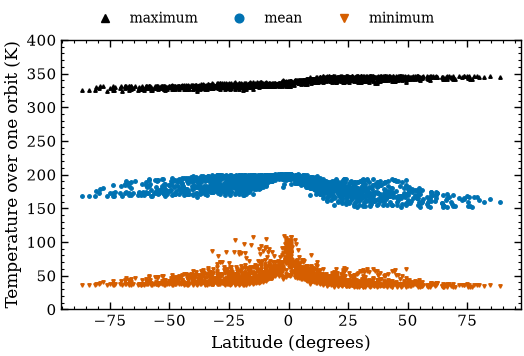

In [9]:
ORBIT = ROOT / "output" / "asteroid_eros_orbit"
if not (ORBIT / "orbit_sites.csv").is_file():
    raise RuntimeError(
        "Section 4 needs the one-orbit run (about 10 minutes on four cores). From the repository "
        "root run\n    ./build/bin/ptm_thermal_sim --config examples/asteroid_eros_orbit.yaml\n"
        "and then run this cell again.")
orbit = Results(ORBIT, body_radius_km=8.41)
tmax, tmin, tavg = (orbit.stat("temperature", m) for m in ("max", "min", "avg"))
hot, cold = np.argmax(tmax), np.argmin(tmin)
print(f"hottest face {tmax[hot]:.1f} K at latitude {orbit.lat[hot]:.0f}, "
      f"coldest face {tmin[cold]:.1f} K at latitude {orbit.lat[cold]:.0f}")
print(f"orbit-mean temperature {np.average(tavg, weights=orbit.face_areas_m2):.1f} K (area-weighted)")

fig, ax = plt.subplots(figsize=(plots.COLUMN_W * 1.5, 3.6), layout="constrained")
for values, label, marker in ((tmax, "maximum", "^"), (tavg, "mean", "o"), (tmin, "minimum", "v")):
    ax.plot(orbit.lat, values, marker, ms=2.5, ls="none", label=label)
ax.set_xlabel("Latitude (degrees)")
ax.set_ylabel("Temperature over one orbit (K)")
ax.set_ylim(0, 400)
fig.legend(loc="outside upper center", ncol=3, markerscale=2.5);

The maximum is similar at all latitudes, because the pole of Eros lies close to its orbital
plane and every latitude faces the Sun at some season. The minimum is lowest at high latitudes,
where a face spends months in darkness.

The site series show when the extremes occur. The file has one row per output and a column of
surface temperature per site. The next cell reduces each site to its daily maximum and minimum
and plots them through the orbit.

equator_0  T_max  338.6 K on 1997-12-12, T_min   66.0 K on 1997-08-12
equator_90 T_max  336.9 K on 1997-12-08, T_min   70.7 K on 1997-08-08
north_60   T_max  345.9 K on 1998-02-01, T_min   36.2 K on 1997-10-30


south_45   T_max  332.5 K on 1997-11-02, T_min   51.3 K on 1998-05-07


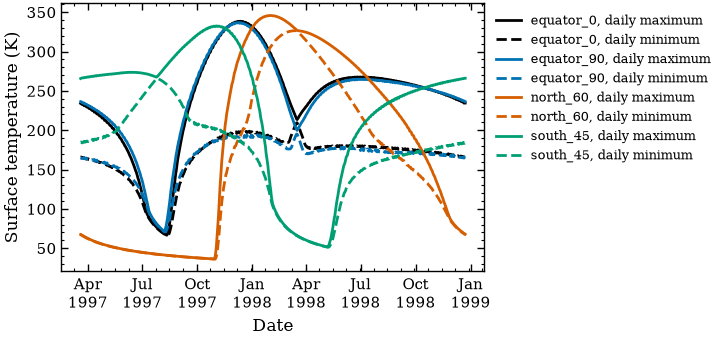

In [10]:
table = np.genfromtxt(ORBIT / "orbit_sites.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
table = table[table["Time"] >= "1997-03-20T11:00:00"]          # drop the spin-up rows
days = np.array([t[:10] for t in table["Time"]], dtype="datetime64[D]")
unique_days = np.unique(days)
fig, ax = plt.subplots(figsize=(plots.DOUBLE_W, 3.4), constrained_layout=True)
for (name, lat, lon), color in zip(sites, ("C0", "C1", "C2", "C3")):
    T = table[f"{name}_Ts"]
    daily_max = np.array([T[days == d].max() for d in unique_days])
    daily_min = np.array([T[days == d].min() for d in unique_days])
    ax.plot(unique_days, daily_max, "-", color=color, label=f"{name}, daily maximum")
    ax.plot(unique_days, daily_min, "--", color=color, label=f"{name}, daily minimum")
    print(f"{name:10s} T_max {T.max():6.1f} K on {table['Time'][np.argmax(T)][:10]}, "
          f"T_min {T.min():6.1f} K on {table['Time'][np.argmin(T)][:10]}")
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_ylabel("Surface temperature (K)")
ax.set_xlabel("Date")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9);

Each site's temperature follows both the heliocentric distance, from 1.13 AU at perihelion to
1.78 AU at aphelion, and the season, as the sub-solar latitude moves across the body. The sites at
60° N and 45° S spend months in darkness, where their daily maximum and minimum meet, and in
early 1998 the northern site is in continuous daylight, with a daily minimum close to its
maximum.

## 5. Exercises

1. Make a second Eros run with `--radiation-exchange` (tutorial 6, "Self-heating") and map the
   difference at closest approach. Where on the shape is self-heating significant?
2. Change the output window of `examples/asteroid_eros.yaml` to the minutes around another
   encounter (`simulation.start_time`, `duration_days` and `timesteps`), keeping the spin-up.
3. Run the sphere at thermal inertias of 50 and 800 SI (`--constant-thermal-inertia`) and compare
   the diurnal curves of section 1 with the thermal parameter.